# Evaluation

In [9]:
import matplotlib.pyplot as plt
import numpy as np

In [10]:
q = {
    'satellite_imagery_analysis': [
        'satellite imagery analysis deep learning',
        'satelite image segmentation convolutional neural network',
        'deep learning approaches for analyzing multispectral satellite imagery for vegetation health monitoring',
        'how to classify land cover change from Sentinel-2 images using CNNs'
    ],
    'earth_observation': [
        'earth observation machine learning',
        'EO satellite sensors atmospheric parameter retrieval',
        'how can atmospheric parameters be reconstructed from earth observation data?',
        'machine learning retrieval of soil moisture from microwave remote sensing data'
    ],
    'natural_language_processing': [
        'NLP for scientific paper retrieval in space mission planning',
        'transformer models summarizing satellite telemetry research articles',
        'how can NLP be used to find relevant papers on robotics control in spacecraft?',
        'using BERT to extract key findings from Earth observation research articles'
    ],
    'robotics_in_spacecraft': [
        'robotics in spacecraft',
        'AI robotics autonomous spacecraft control systems',
        'how to optimize neural networks for autonomous spacecraft navigation?',
        'deep reinforcement learning for satellite docking manoeuvres'
    ],
    'remote_sensing': [
        'remote sensing hyperspectral image unmixing deep learning',
        'SAR InSAR deformation detection earth observation',
        'AI techniques for spectral unmixing of hyperspectral remote sensing data',
        'how to detect urban land subsidence via InSAR for remote sensing analysis'
    ]
}

# Relevant Ranking: Binary
# K: 10

In [11]:
# Manual evalated query-result data

results = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
results = [str(i) for i in results]

rel_1_1 = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rel_1_2 = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rel_1_3 = [1, 3, 4, 8]
rel_1_4 = [0, 1, 3, 4, 5, 6, 7, 8, 9]

rel_2_1 = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rel_2_2 = [0, 2, 3, 4, 5, 7, 8]
rel_2_3 = [1, 2]
rel_2_4 = [0, 1, 2, 4, 7]

# Maybe NLP in this domain of papers is not common
rel_3_1 = [2, 7]
rel_3_2 = []
rel_3_3 = []
rel_3_4 = []

rel_4_1 = [0, 1, 2, 4, 5, 6, 7]
rel_4_2 = [0, 1, 2, 3, 5, 6, 7, 8, 9]
rel_4_3 = [5, 6, 7, 9]
rel_4_4 = [1, 2, 3, 4]

rel_5_1 = [0, 2, 3, 6, 9]
rel_5_2 = [0, 1, 2, 4, 7, 8, ]
rel_5_3 = [0, 1, 2, 3, 4, 5, 7, 9]
rel_5_4 = [0, 1, 2, 3, 5, 6, 8, 9]

In [12]:
def list_to_str_set(given_list):
    result = [str(i) for i in given_list]
    result = set(result)
    return result


def average_precision(ranked_list, relevant_set):
    hits = 0
    sum_precisions = 0.0
    for i, doc_id in enumerate(ranked_list, start=1):
        if doc_id in relevant_set:
            hits += 1
            sum_precisions += hits / i
    return sum_precisions / len(relevant_set) if relevant_set else 0.0


def mean_average_precision(all_ranked_lists, all_relevant_sets):
    ap_scores = [
        average_precision(ranked, relevant)
        for ranked, relevant in zip(all_ranked_lists, all_relevant_sets)
    ]
    return sum(ap_scores) / len(ap_scores) if ap_scores else 0.0

In [13]:
relevants = [
             list_to_str_set(rel_1_1), list_to_str_set(rel_1_2), list_to_str_set(rel_1_3), list_to_str_set(rel_1_4),
             list_to_str_set(rel_2_1), list_to_str_set(rel_2_2), list_to_str_set(rel_2_3), list_to_str_set(rel_2_4),
            #  list_to_str_set(rel_3_1), list_to_str_set(rel_3_2), list_to_str_set(rel_3_3), list_to_str_set(rel_3_4),
             list_to_str_set(rel_4_1), list_to_str_set(rel_4_2), list_to_str_set(rel_4_3), list_to_str_set(rel_4_4),
             list_to_str_set(rel_5_1), list_to_str_set(rel_5_2), list_to_str_set(rel_5_3), list_to_str_set(rel_5_4)

            ]

print(mean_average_precision(results, relevants))

0.0865079365079365


In [14]:
def compute_pr_curve_at_k(ranked_list, relevant_set, max_k=10):
    precisions = []
    recalls = []
    total_relevant = len(relevant_set)

    retrieved = set()
    hits = 0

    for k in range(1, max_k + 1):
        doc = ranked_list[k-1]
        if doc in relevant_set:
            hits += 1
        retrieved.add(doc)
        precision_k = hits / k
        recall_k = hits / total_relevant if total_relevant else 0.0
        precisions.append(precision_k)
        recalls.append(recall_k)
    return recalls, precisions

def average_pr_curves(curves):
    rs = np.linspace(0, 1, 11)
    pm = []
    for recall, precision in curves:
        pm.append(np.interp(rs, recall, precision))
    mean_p = np.mean(pm, axis=0)
    return rs, mean_p


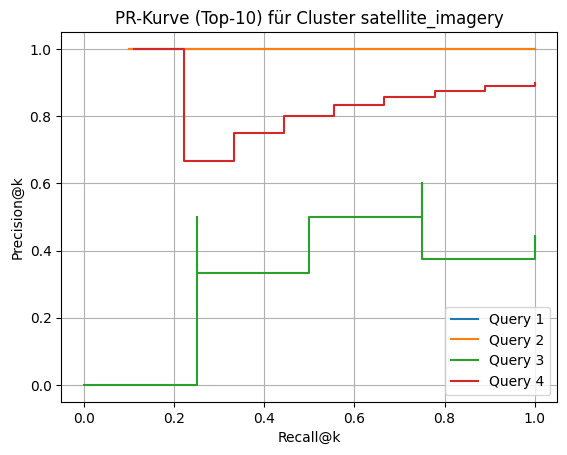

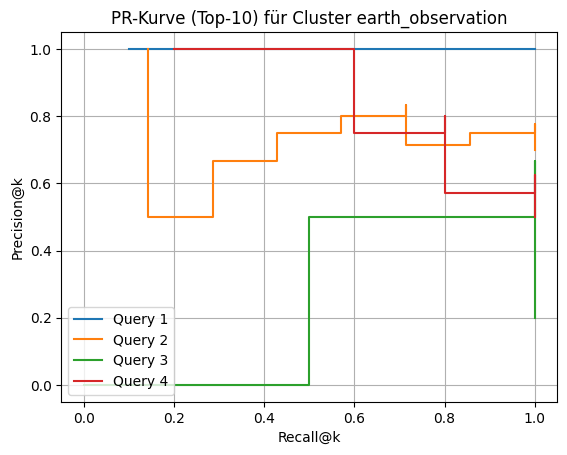

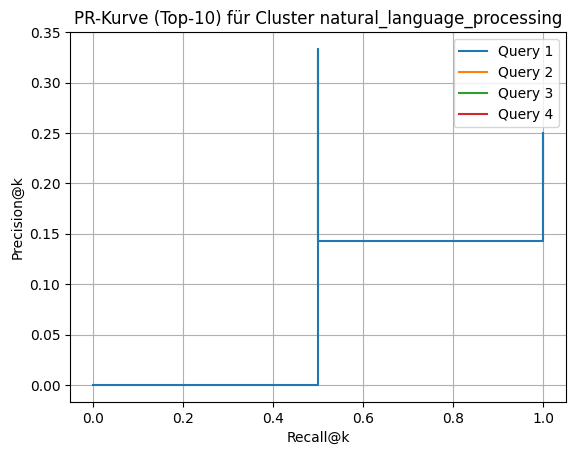

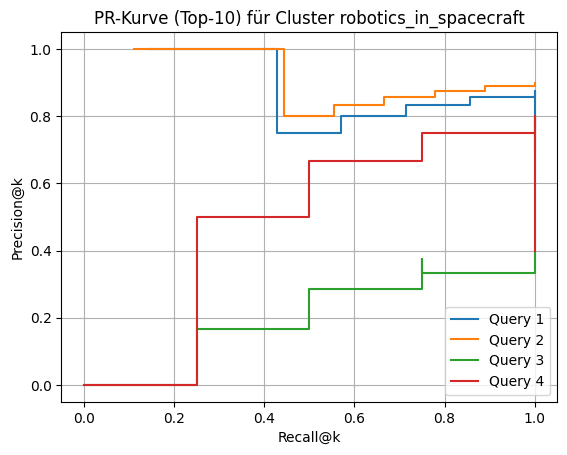

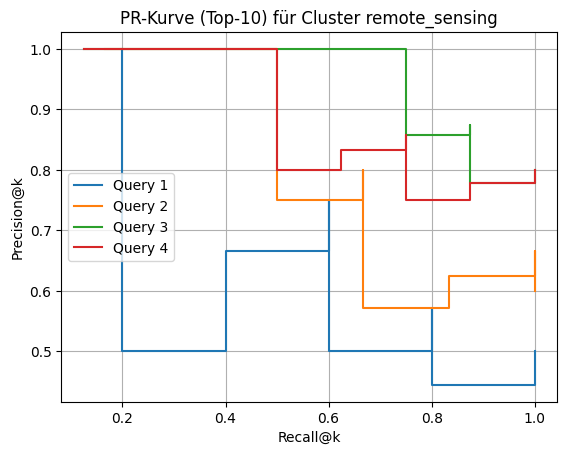

In [15]:
clusters = {
  "satellite_imagery": [
      (results, list_to_str_set(rel_1_1)), (results, list_to_str_set(rel_1_2)), (results, list_to_str_set(rel_1_3)), (results, list_to_str_set(rel_1_4))
      ],
  "earth_observation": [
      (results, list_to_str_set(rel_2_1)), (results, list_to_str_set(rel_2_2)), (results, list_to_str_set(rel_2_3)), (results, list_to_str_set(rel_2_4))
  ],
  "natural_language_processing": [
      (results, list_to_str_set(rel_3_1)), (results, list_to_str_set(rel_3_2)), (results, list_to_str_set(rel_3_3)), (results, list_to_str_set(rel_3_4))
  ],
  "robotics_in_spacecraft": [
      (results, list_to_str_set(rel_4_1)), (results, list_to_str_set(rel_4_2)), (results, list_to_str_set(rel_4_3)), (results, list_to_str_set(rel_4_4))
  ],
  "remote_sensing": [
      (results, list_to_str_set(rel_5_1)), (results, list_to_str_set(rel_5_2)), (results, list_to_str_set(rel_5_3)), (results, list_to_str_set(rel_5_4))
  ]
}

for cluster_name, queries in clusters.items():
    plt.figure()
    for i, (ranked_list, relevant_set) in enumerate(queries, start=1):
        rec, prec = compute_pr_curve_at_k(ranked_list, relevant_set, max_k=10)
        plt.step(rec, prec, where='post', label=f'Query {i}')
    plt.xlabel('Recall@k')
    plt.ylabel('Precision@k')
    plt.title(f'PR-Kurve (Top-10) für Cluster {cluster_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

In [16]:
def compute_ap_at_10(ranked_list, relevant_set, k=10):
    hits = 0
    sum_prec = 0.0
    for i in range(min(k, len(ranked_list))):
        if ranked_list[i] in relevant_set:
            hits += 1
            sum_prec += hits / (i + 1)
    return sum_prec / len(relevant_set) if hits > 0 else 0.0

for cluster_name, queries in clusters.items():
    ap10_values = []
    for ranked_list, relevant_set in queries:
        ap10 = compute_ap_at_10(ranked_list, relevant_set, k=10)
        ap10_values.append(ap10)
        print(f"Cluster {cluster_name}, Query -> AP@10 = {ap10:.3f}")
    mean_ap10 = np.mean(ap10_values)
    print(f"→ Mean AP@10 für Cluster '{cluster_name}': {mean_ap10:.3f}\n")

all_ap10 = [compute_ap_at_10(ranked, relevant) for queries in clusters.values() for ranked, relevant in queries]
print(f"Global Mean AP@10 über alle Queries: {np.mean(all_ap10):.3f}")

Cluster satellite_imagery, Query -> AP@10 = 1.000
Cluster satellite_imagery, Query -> AP@10 = 1.000
Cluster satellite_imagery, Query -> AP@10 = 0.511
Cluster satellite_imagery, Query -> AP@10 = 0.878
→ Mean AP@10 für Cluster 'satellite_imagery': 0.847

Cluster earth_observation, Query -> AP@10 = 1.000
Cluster earth_observation, Query -> AP@10 = 0.797
Cluster earth_observation, Query -> AP@10 = 0.583
Cluster earth_observation, Query -> AP@10 = 0.885
→ Mean AP@10 für Cluster 'earth_observation': 0.816

Cluster natural_language_processing, Query -> AP@10 = 0.292
Cluster natural_language_processing, Query -> AP@10 = 0.000
Cluster natural_language_processing, Query -> AP@10 = 0.000
Cluster natural_language_processing, Query -> AP@10 = 0.000
→ Mean AP@10 für Cluster 'natural_language_processing': 0.073

Cluster robotics_in_spacecraft, Query -> AP@10 = 0.909
Cluster robotics_in_spacecraft, Query -> AP@10 = 0.928
Cluster robotics_in_spacecraft, Query -> AP@10 = 0.307
Cluster robotics_in_spacec